# Button pressing

Loads the runs in `outputs/button_pressing/` and picks out the stretch of each one where
nothing was being touched.

`button_pressing` is scripted: four strengths, five repeats each, identical goals every run,
so the repeats give the error bar.

Everything positional is taken from the run itself, never from the config, and the same goes
for the strength, which is read out of `k_params` over the measurement window.

**The arm does not stay in a plane.** The tip goal moves in x-y at a locked z, gravity pulls
along -y, and the recorded poses leave the y = 0 plane by up to 16 cm. A single x-z view of
the backbone is a shadow: one run shows the arm grazing the obstacle at 0.8 cm when the real
distance is 12.2 cm. So the geometry figure shows both projections plus the true 3-D distance
along the backbone, which is the only one of the three that can be compared against sigma.

Runs recorded before the logging was widened carry a smaller field set; the cells below
detect what is there and draw what they can.


In [1]:
import sys, os, importlib.util
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_1P5, FIG_W_DOUBLE, set_font_size
from FK_Multi import FK_Multi
from VMC_utils.ConfigHelpers import strip_repeat
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

import glob
import numpy as np
import matplotlib.pyplot as plt

G_TO_N = 9.80665e-3   # load cell reports grams
S_BACKBONE = np.linspace(0.0, 1.0, 25)
SETTLE_S = 1.0        # [s] dropped from the front of a hold window, to let the arm arrive


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the runs it came from."""
    for ext in ('pdf', 'svg'):
        fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))

In [2]:
def load_cfg(name):
    """Import a config variant by file name without copying it into place."""
    spec = importlib.util.spec_from_file_location('cfg_' + name, f'GUI_MultiVMC_Config_{name}.py')
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def list_runs(folder):
    """Every run recorded in outputs/<folder>/, by name.

    Two kinds of file can be left behind by a run that did not exit cleanly:
    `<run>.autosave.npz`, the last 30-second checkpoint, which is complete and
    readable up to where it got to; and `<run>.npz.part.npz`, a final write that
    was interrupted, which is truncated and is skipped."""
    names = []
    for path in sorted(glob.glob(os.path.join('outputs', folder, '*.npz'))):
        name = os.path.splitext(os.path.basename(path))[0]
        if name.endswith('.part'):
            print(f'[skip] {name}.npz -- interrupted write, not readable')
            continue
        if name.endswith('.autosave'):
            print(f'[note] {name}.npz is a checkpoint: the run did not exit cleanly, '
                  'so it ends at the last one taken')
        names.append(name)
    return names


def hold_window(d, tol=1e-9, settle=SETTLE_S, mark_index=0):
    """The measurement window.

    If the run carries an operator mark -- Ctrl+C in the torque node's terminal
    when the tip reached the button -- the window starts there and runs until something
    is touched again. `mark_index` picks which mark, when a run has several.

    Without one it falls back to the longest stretch where NOTHING moved: every
    goal x/y, every spring parameter, every damper parameter. That fallback cannot
    tell "on the button" from "let go of the mouse", and it silently spans a
    stiffness change if one happened mid-run, averaging two different
    experiments together.

    Only x/y of the goal count as motion here -- goal z is excluded on purpose.
    In `_person`/`_card_castle` (GOAL_Z_TRACK) every goal z re-tracks its own
    attachment point every control tick, so it never repeats bit-for-bit even
    while the arm is genuinely still: it wiggles at the ~1e-5 m level from pure
    FK/float noise. Counting that as "changed" fragmented the hold segment into
    single ticks for those two folders (a few ms instead of several seconds),
    while `_button`'s locked goal z was never affected. `_button`'s x/y-only
    signal is unchanged by this, since its goal was never dragged mid-hold.

    Either way the first SETTLE_S is dropped, so the arm's arrival is not
    averaged in with where it arrived."""
    t   = d['t']
    sig = [d['goal'][:, :, :2].reshape(len(t), -1), d['k_params']]
    if 'c_params' in d:
        sig.append(d['c_params'])
    sig = np.hstack([np.asarray(s, dtype=float) for s in sig])

    changed = np.r_[True, np.abs(np.diff(sig, axis=0)).max(axis=1) > tol]
    seg     = np.cumsum(changed)

    marks = np.asarray(d.get('marks_t', []), dtype=float)
    marks = marks[np.isfinite(marks) & (marks >= t[0]) & (marks <= t[-1])]
    if len(marks) > mark_index:
        m0   = marks[mark_index]
        hold = (seg == seg[int(np.searchsorted(t, m0))]) & (t >= m0)
    else:
        hold = seg == np.bincount(seg).argmax()

    trimmed = hold & (t >= t[hold][0] + settle) if hold.any() else hold
    return trimmed if trimmed.any() else hold   # a mark right before Ctrl+C


def load_run(folder, name):
    """One run, with its hold window marked and the newer log channels passed
    through when the file has them."""
    raw = np.load(os.path.join('outputs', folder, name + '.npz'), allow_pickle=True)
    d   = {k: raw[k] for k in raw.files}   # forces the read now, not lazily

    hold     = hold_window(d)
    tip_goal = d['goal'][:, 0, :]
    k_gauss  = d['k_params'][:, 1]

    r = dict(name=name, folder=folder, raw=d, t=d['t'], hold=hold,
             goal=d['goal'], comp_pos=d['comp_pos'],
             q_motor=d['q_motor'], tau=d['tau'],
             k_params=d['k_params'], k_gauss=k_gauss,
             force_n=d['force'] * G_TO_N,
             s_params=d['comp_s_params'],
             comp_names=[str(n) for n in d['comp_names']],
             tau_limit=float(d['tau_limit'][0]),
             strength=float(k_gauss[hold].mean()),
             target=tip_goal[hold].mean(axis=0),
             obstacle=d['goal'][hold, 1, :].mean(axis=0))

    # ── Channels only newer runs carry ────────────────────────────────────────
    r['f_comp']    = d.get('f_comp')            # (n, N_VC, 3) [N] per element
    r['comp_vel']  = d.get('comp_vel')          # (n, N_VC, 3) [m/s]
    r['c_params']  = d.get('c_params')
    r['force_age'] = d.get('force_age')
    r['tau_raw']   = d.get('tau_raw', d['tau'])  # pre-limiter torque, else the clipped one
    r['clipped']   = np.any(np.abs(r['tau_raw']) > r['tau_limit'] + 1e-12, axis=1)
    r['has_pre']   = bool((d['t'] < 0).any())    # logged before the GUI connected
    r['force_live'] = bool(np.any(d['force'] != 0.0))
    # The button sweep records `weak_r1`..`weak_r5`: same condition, separate
    # recordings. Group by the condition, keep the repeat for labelling. A
    # person run is one file per level, so it is its own group.
    r['condition']   = strip_repeat(name)
    r['repeat']      = name[len(r['condition']):].lstrip('_') or None
    r['marks_t']     = np.asarray(d.get('marks_t', []), dtype=float)
    r['marks_label'] = [str(x) for x in d.get('marks_label', [])]
    return r


def backbone(run, hold=None):
    """FK backbone at the mean pose over a window (the hold window by default)."""
    mask = run['hold'] if hold is None else hold
    q_ss = run['q_motor'][mask].mean(axis=0)
    return np.array([FK_Multi(q_ss, s)[:3] for s in S_BACKBONE])


def load_all(folder):
    """Every readable run in a folder. One unreadable file does not take the
    rest of the notebook down with it."""
    runs = []
    for name in list_runs(folder):
        try:
            runs.append(load_run(folder, name))
        except Exception as exc:
            print(f'[skip] {name}.npz -- {type(exc).__name__}: {exc}')
    # Sweep order, not alphabetical: with repeats the folder holds 20 files and
    # `medium_r1` sorting before `no_gauss_r1` makes every legend read backwards.
    # Runs all at one strength (the person) fall back to sorting by name.
    return sorted(runs, key=lambda r: (r['strength'], r['name']))


def summary(runs):
    for r in runs:
        b   = backbone(r)
        clr = np.linalg.norm(b - r['obstacle'], axis=1).min()
        tip = r['comp_pos'][r['hold'], 0, :].mean(axis=0)
        r['clearance']   = float(clr)
        r['reach_error'] = float(np.linalg.norm(r['target'] - tip))
        t = r['t'][r['hold']]
        print(f"{r['name']:>14}  strength {r['strength']:6.0f}  "
              f"hold {t[0]:6.1f}-{t[-1]:6.1f}s ({r['hold'].sum():6d} samples)  "
              f"clearance {clr*100:5.1f} cm  reach err {r['reach_error']*100:5.1f} cm  "
              f"clip {100*r['clipped'][r['hold']].mean():4.0f}%  "
              f"force {'live' if r['force_live'] else 'FLAT'}  "
              f"window {'marked' if len(r['marks_t']) else 'inferred'}")

In [3]:
cfg_b  = load_cfg('button')
runs_b = load_all('button_pressing')
if not runs_b:
    print('outputs/button_pressing/ is empty -- record the button runs first '
          '(README: python3 run_sweep.py).')
else:
    summary(runs_b)

   no_gauss_r1  strength      0  hold   56.2-  75.2s (  6253 samples)  clearance   2.2 cm  reach err  23.1 cm  clip    0%  force live  window marked
   no_gauss_r2  strength      0  hold   56.2-  75.2s (  6253 samples)  clearance   2.1 cm  reach err  23.0 cm  clip    0%  force live  window marked
   no_gauss_r3  strength      0  hold   56.2-  75.2s (  6258 samples)  clearance   2.3 cm  reach err  23.1 cm  clip    0%  force live  window marked
   no_gauss_r4  strength      0  hold   56.2-  75.2s (  6264 samples)  clearance   2.2 cm  reach err  23.1 cm  clip    0%  force live  window marked
   no_gauss_r5  strength      0  hold   56.2-  75.2s (  6251 samples)  clearance   2.2 cm  reach err  23.0 cm  clip    0%  force live  window marked
       weak_r1  strength    200  hold   56.2-  75.1s (  6236 samples)  clearance   6.1 cm  reach err  27.6 cm  clip    0%  force live  window marked
       weak_r2  strength    200  hold   56.2-  75.2s (  6264 samples)  clearance   6.2 cm  reach err  27.6

### The run itself

Everything the torque node logged, over the whole run, with the hold window shaded. This is
where a run is judged before any steady-state number is taken from it: whether the ramp went
in, whether a slider moved mid-run, whether the limiter was active, whether the load cell was
alive. `t < 0`, when a run has it, is the stretch before the GUI connected -- the arm was
already being driven towards the config's start goal.

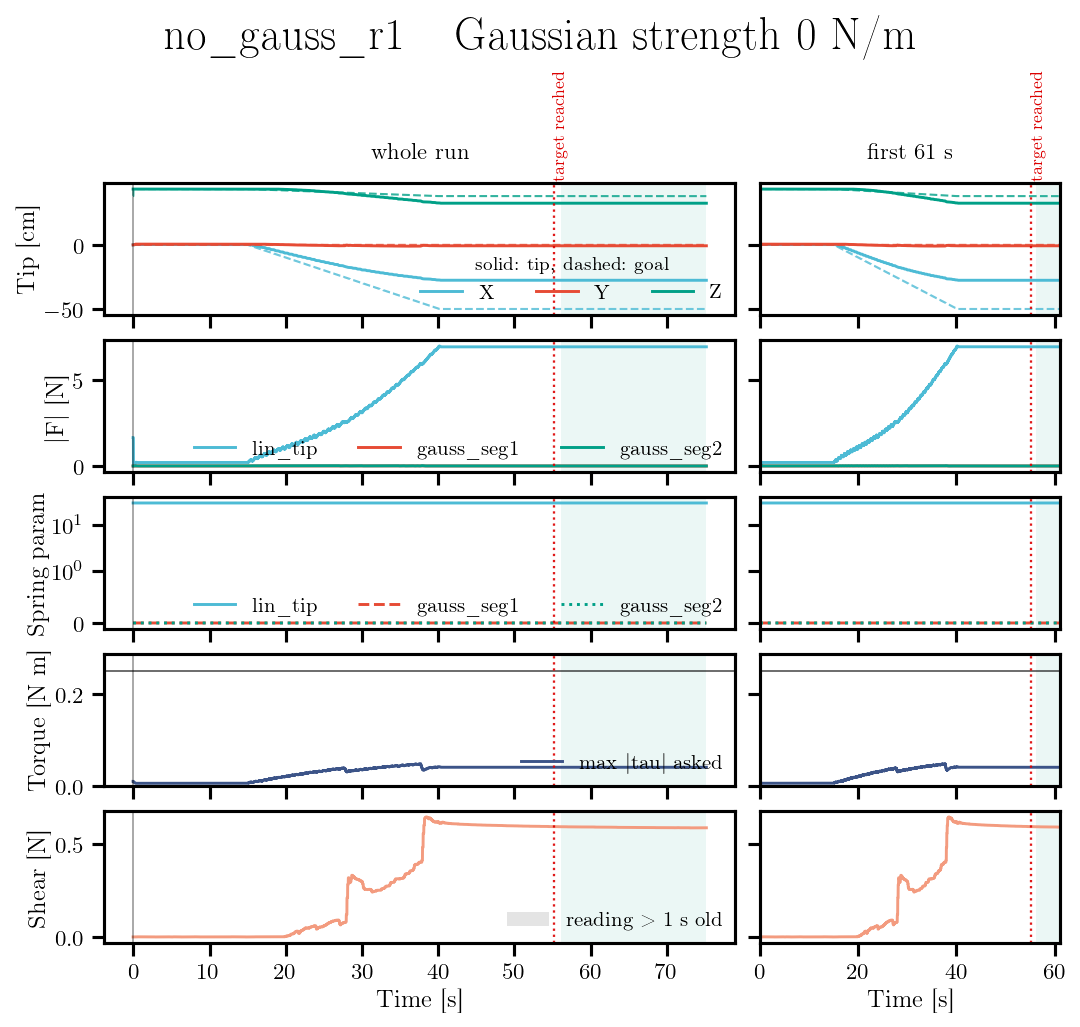

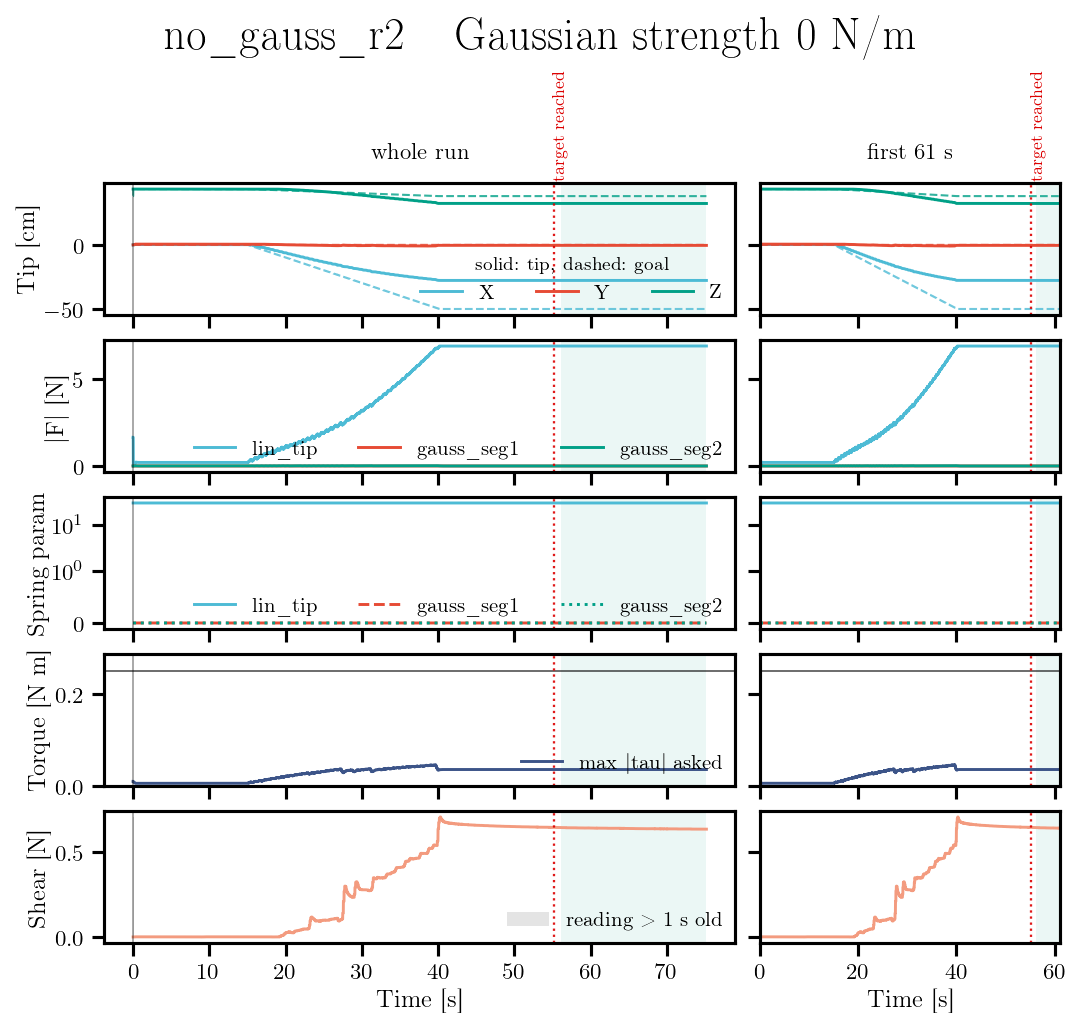

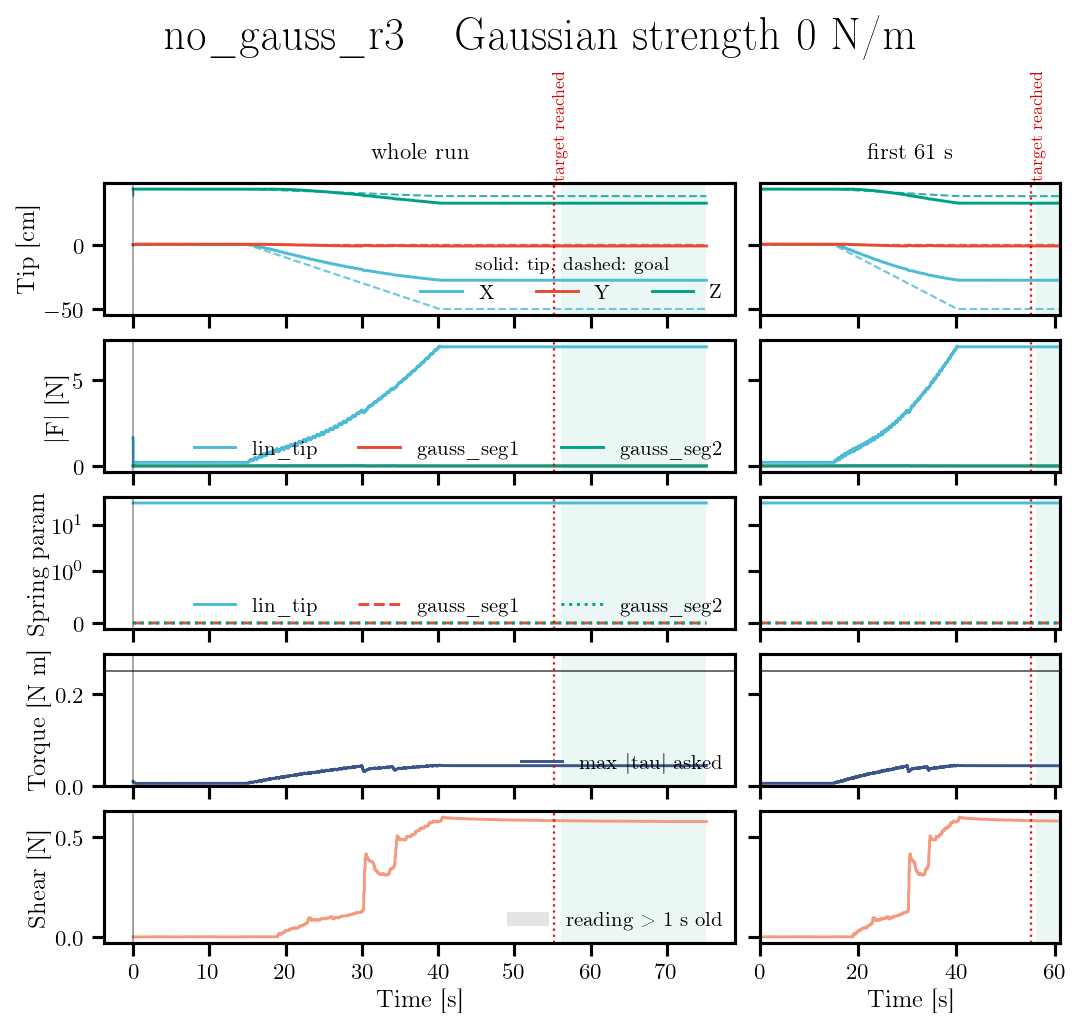

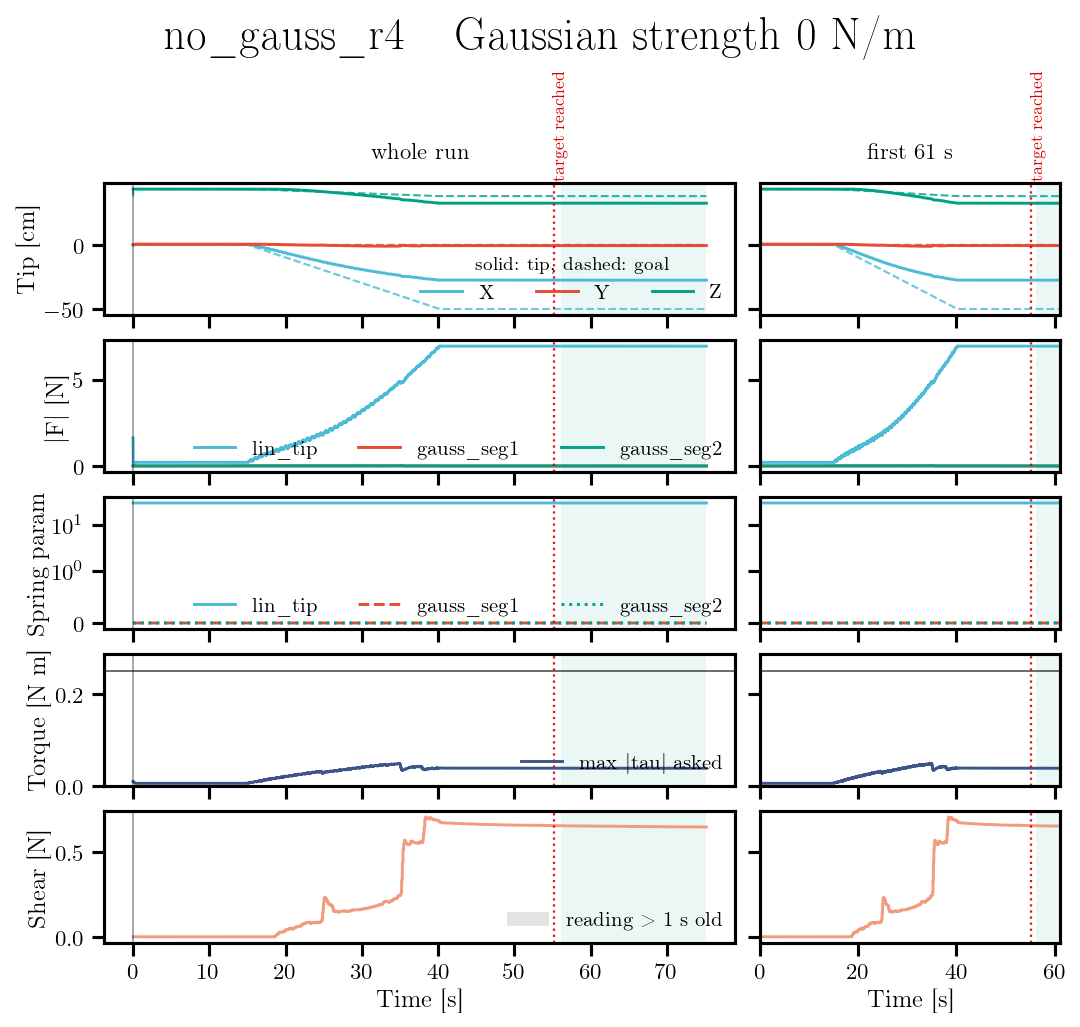

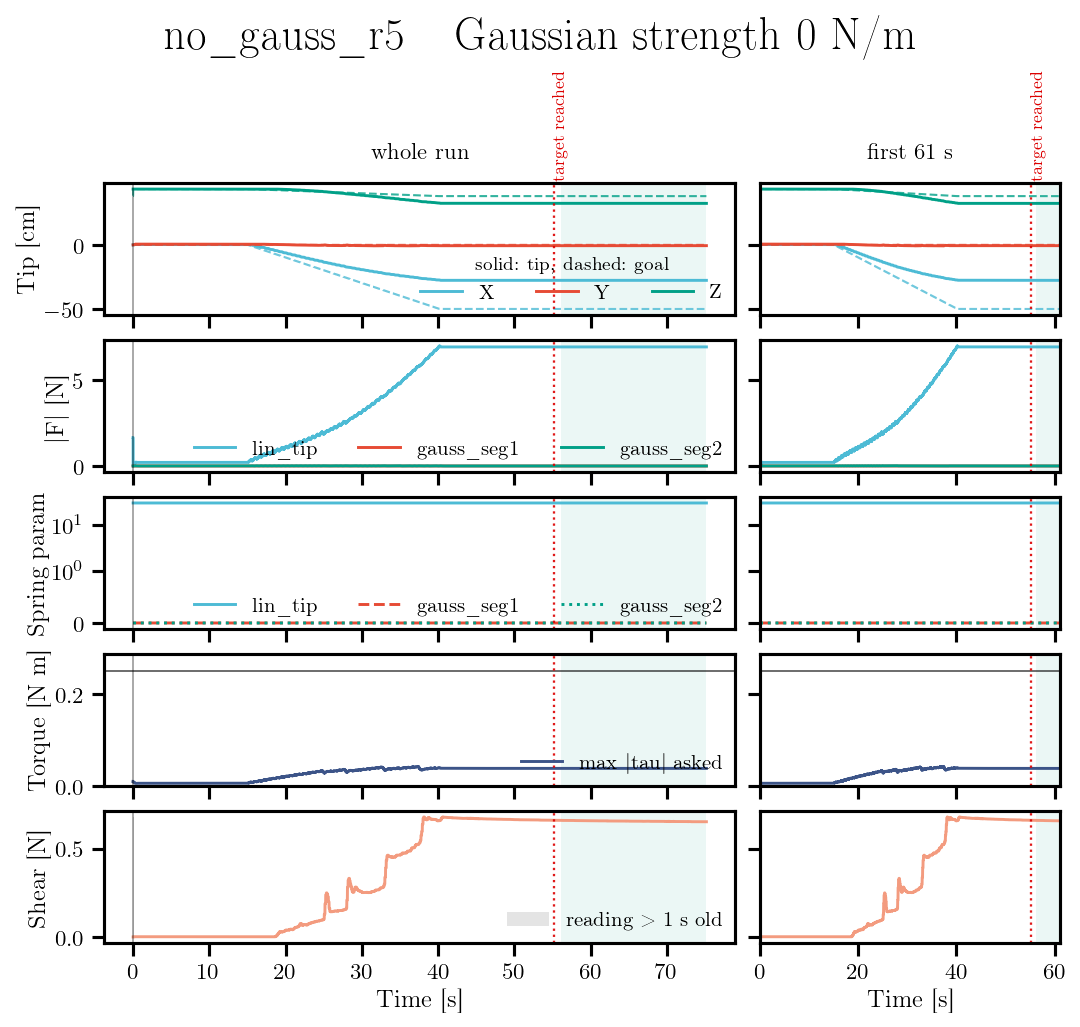

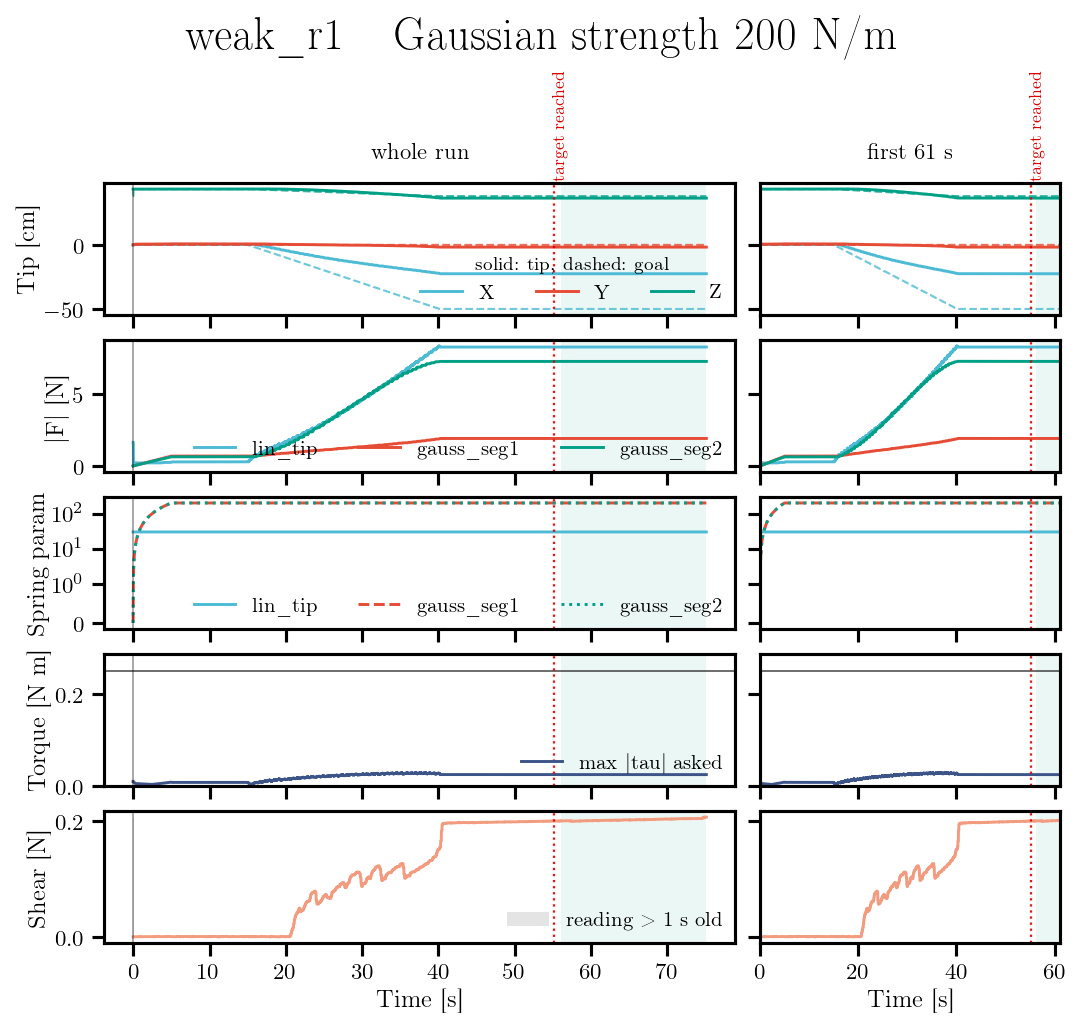

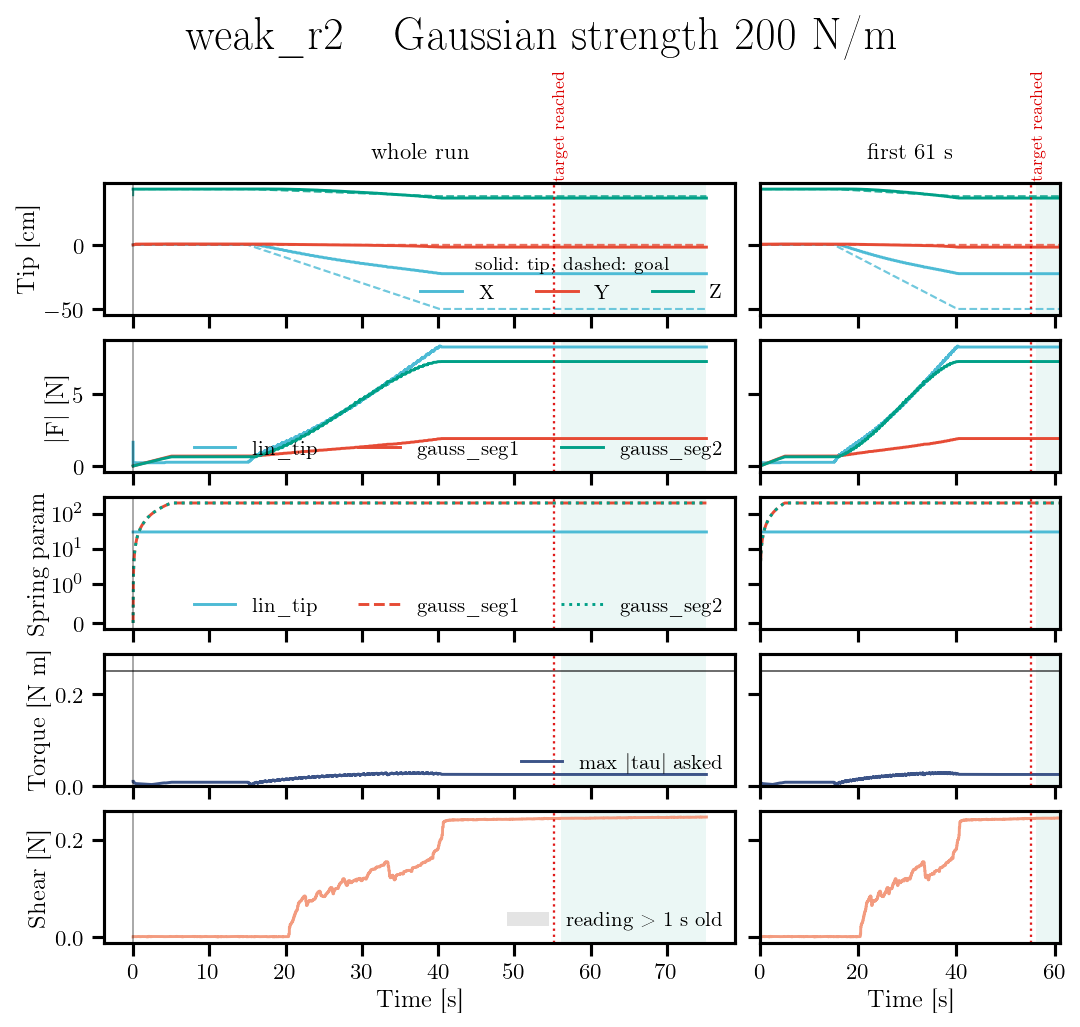

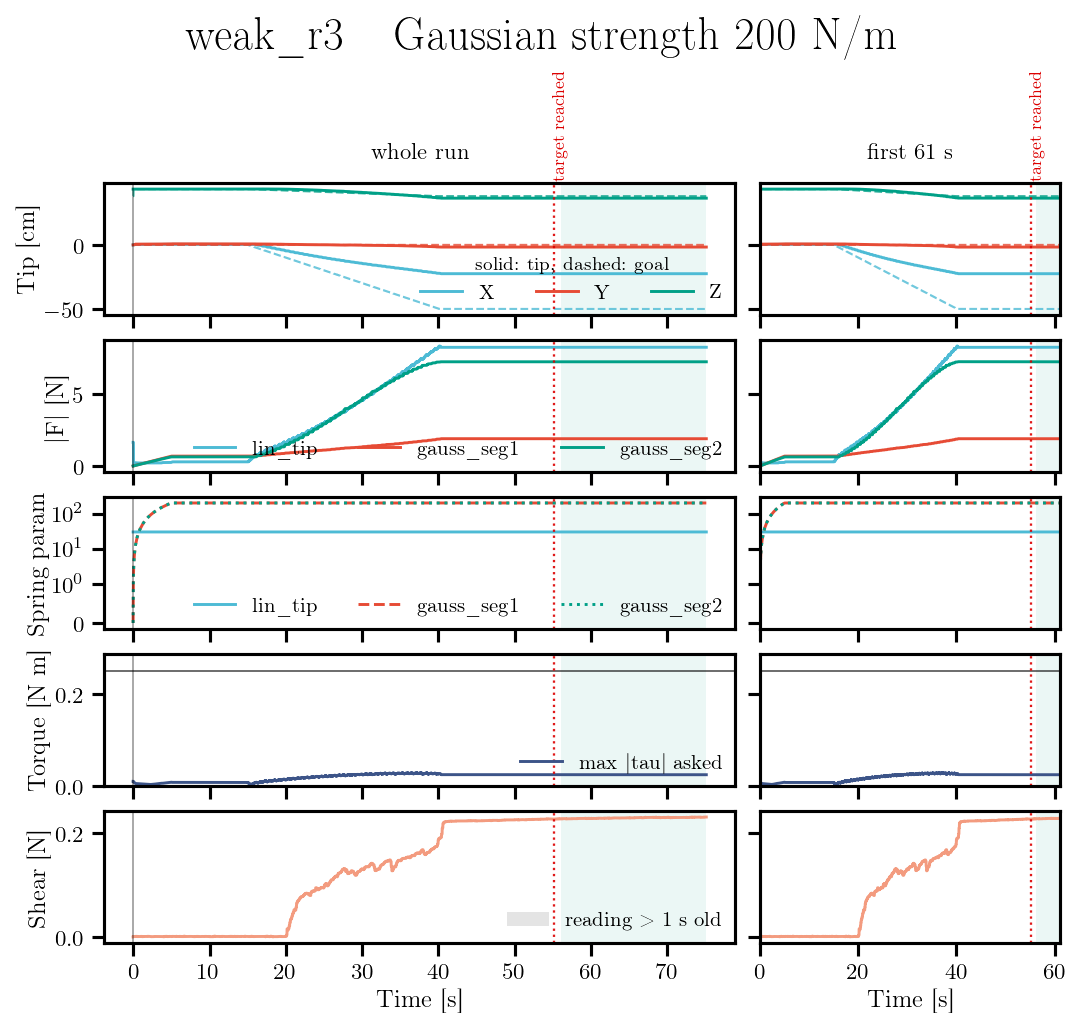

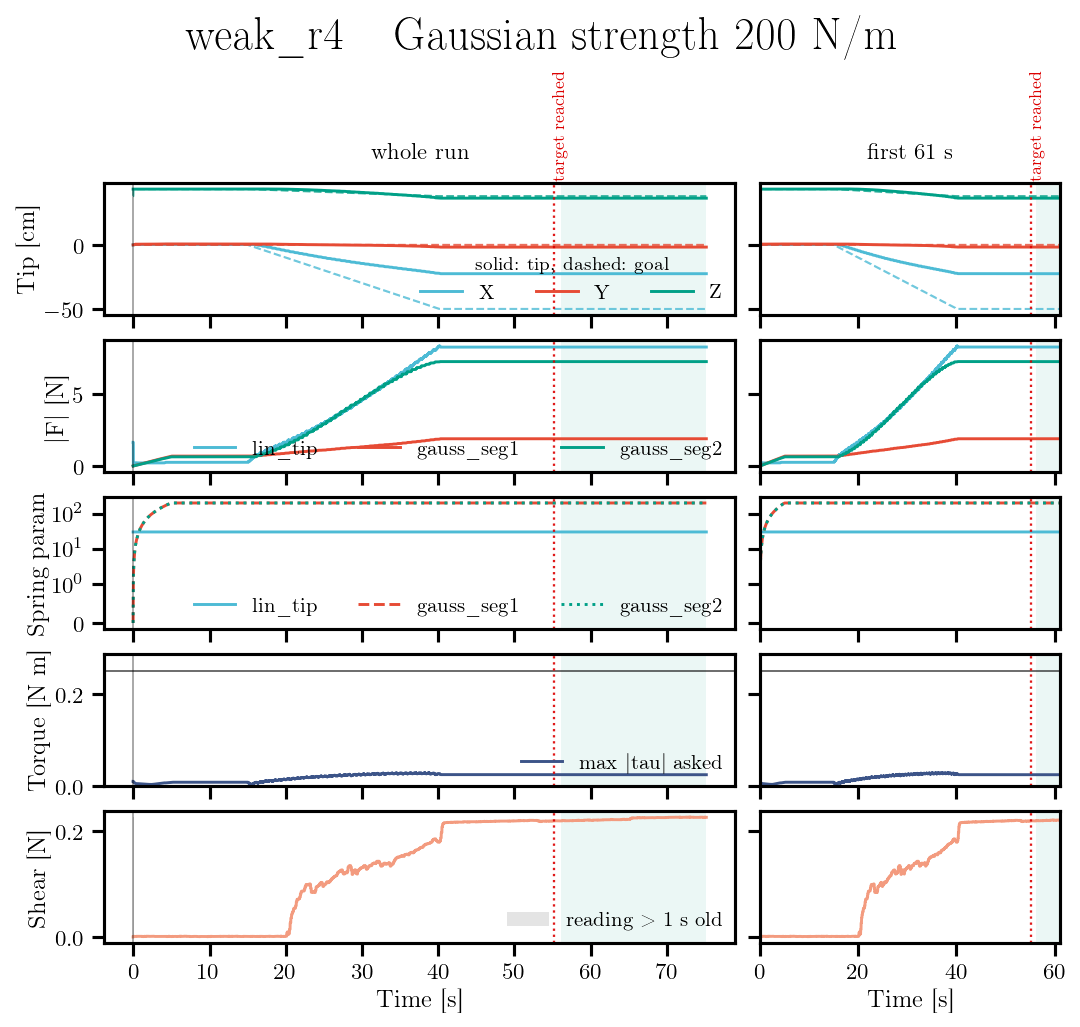

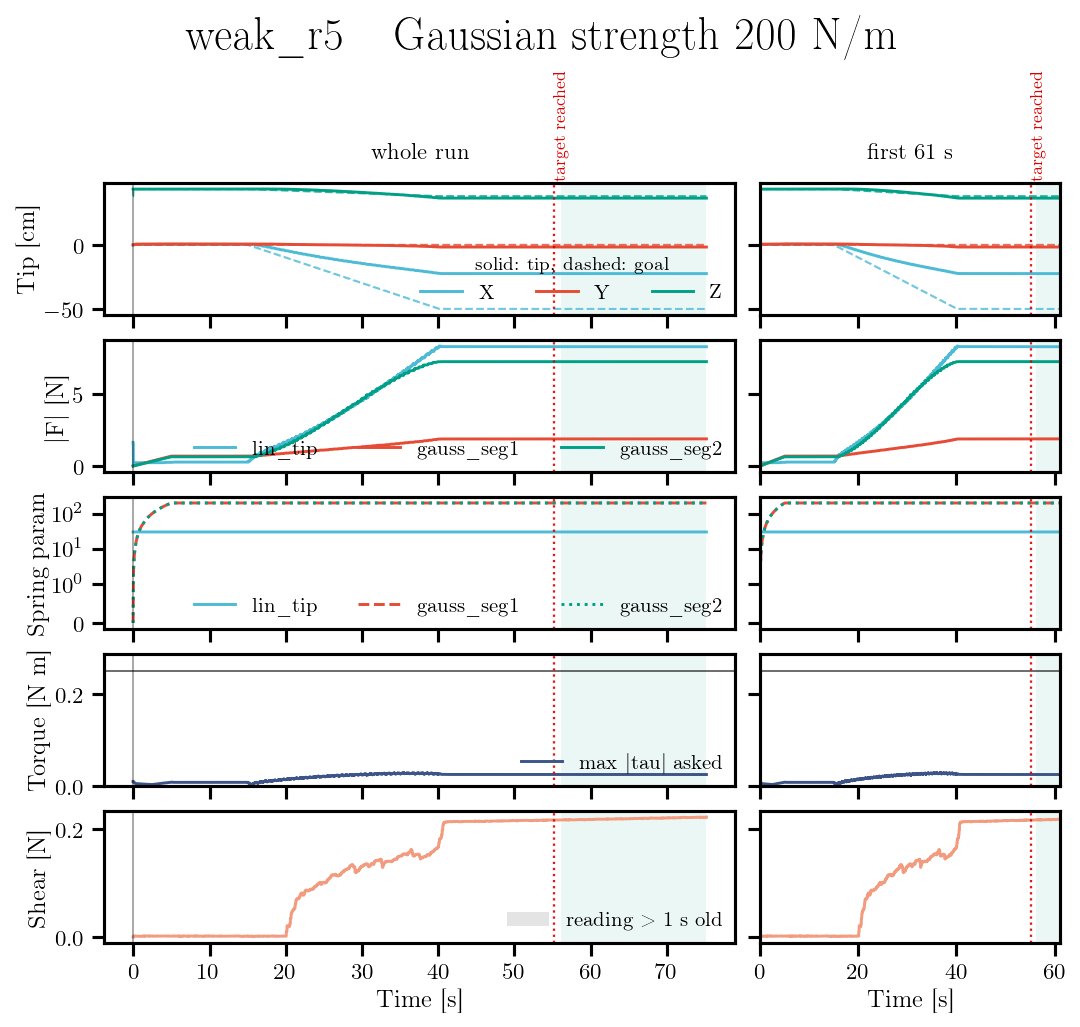

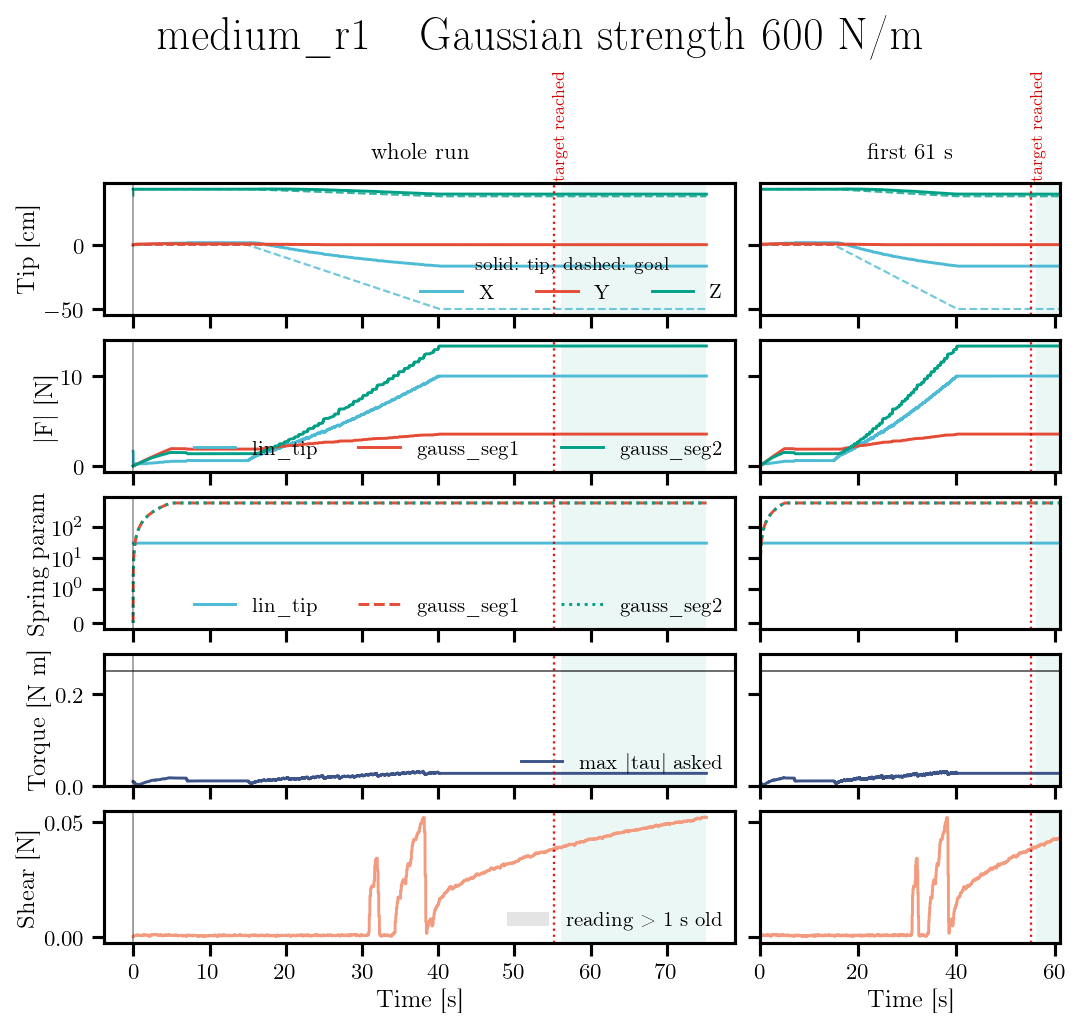

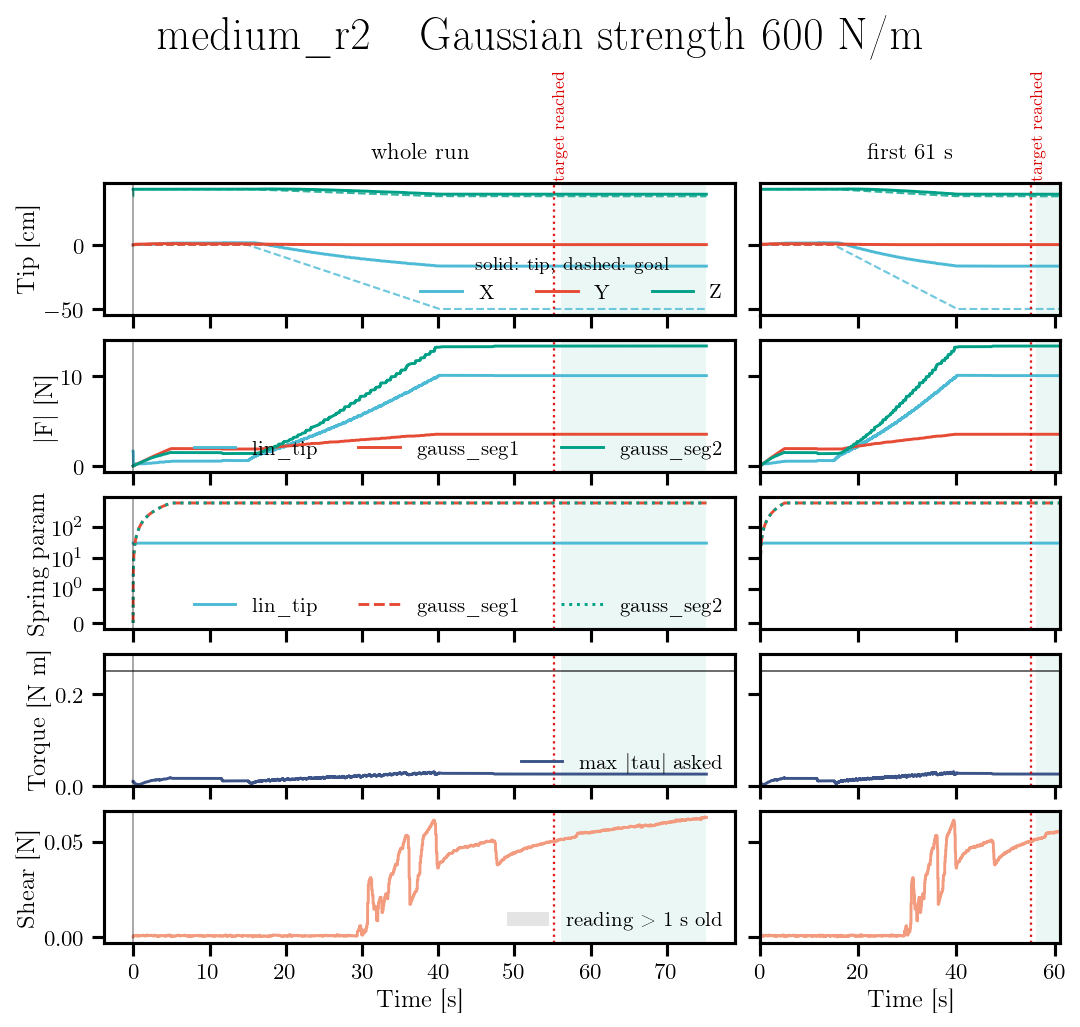

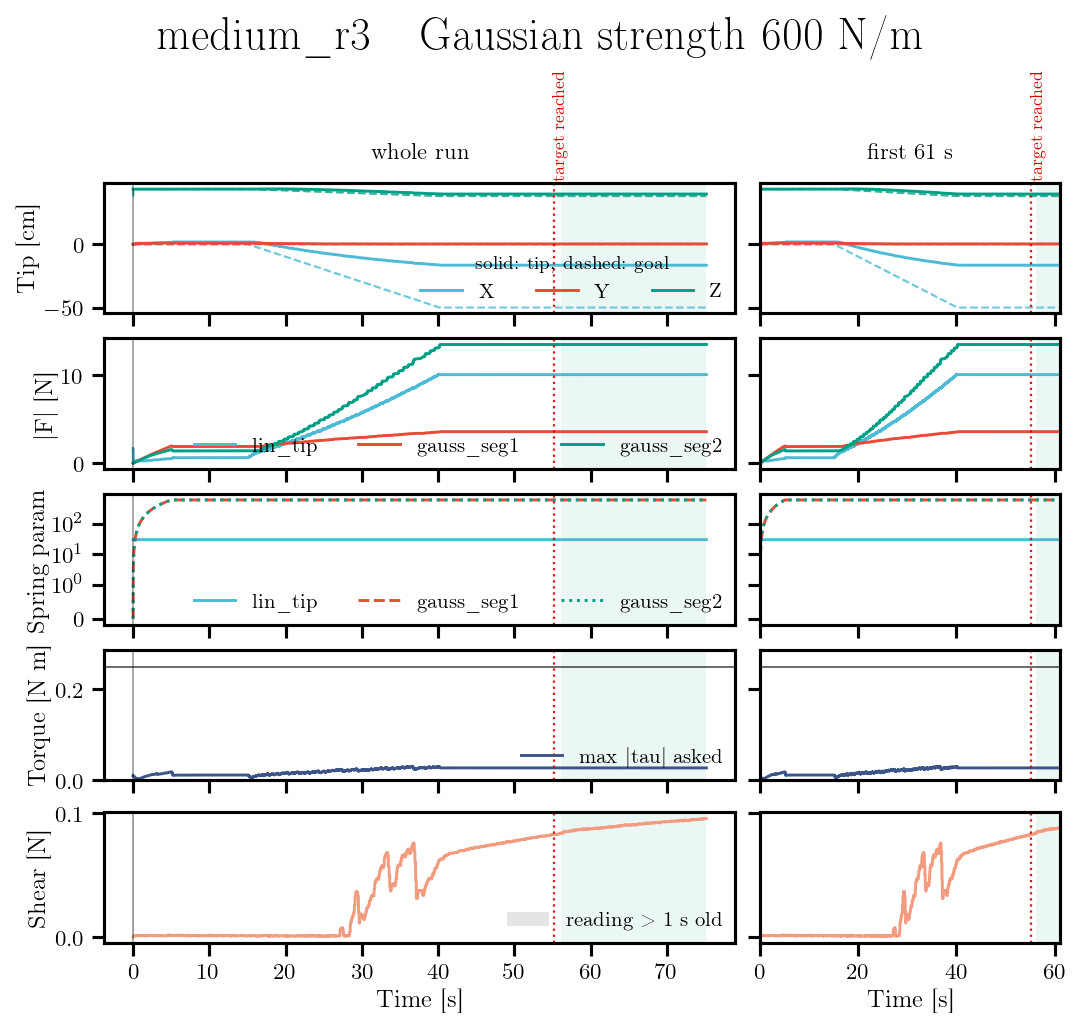

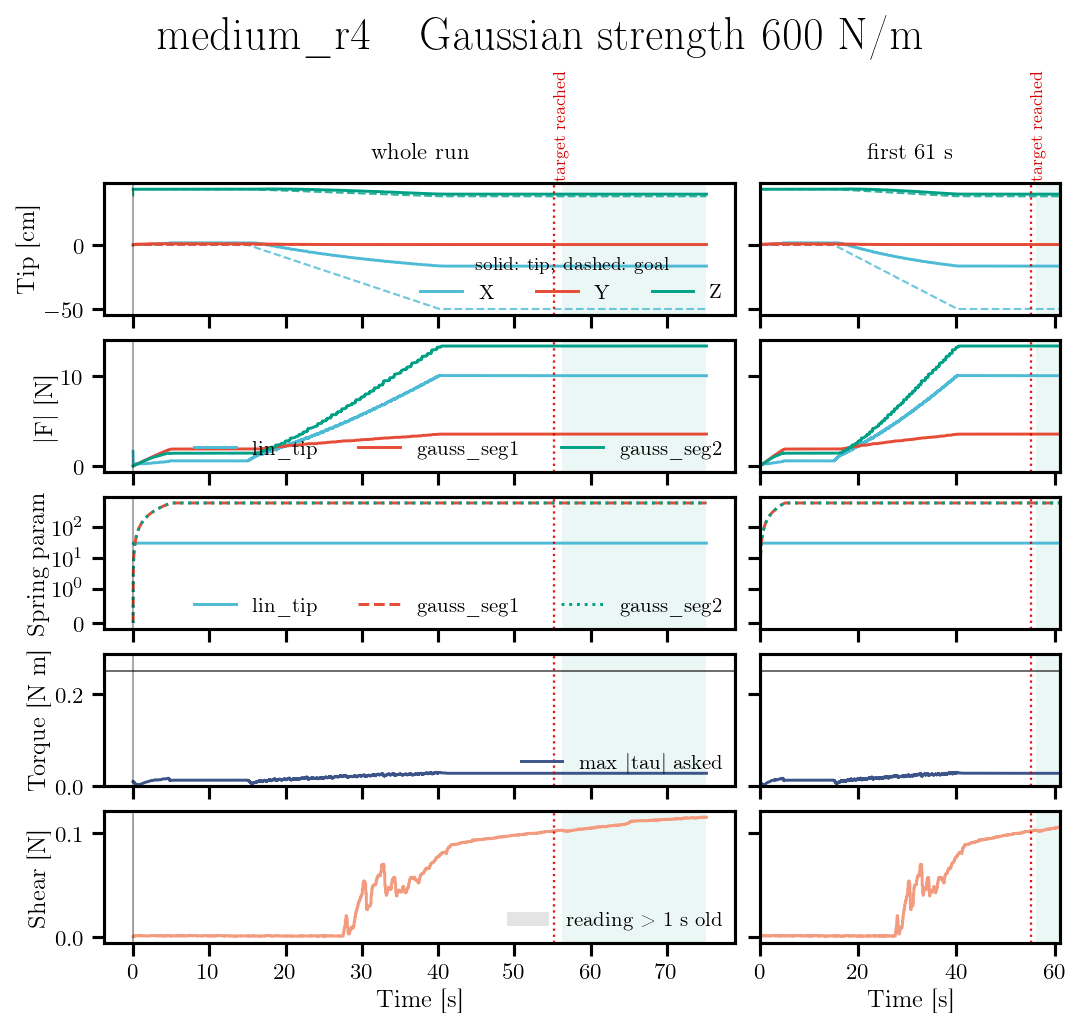

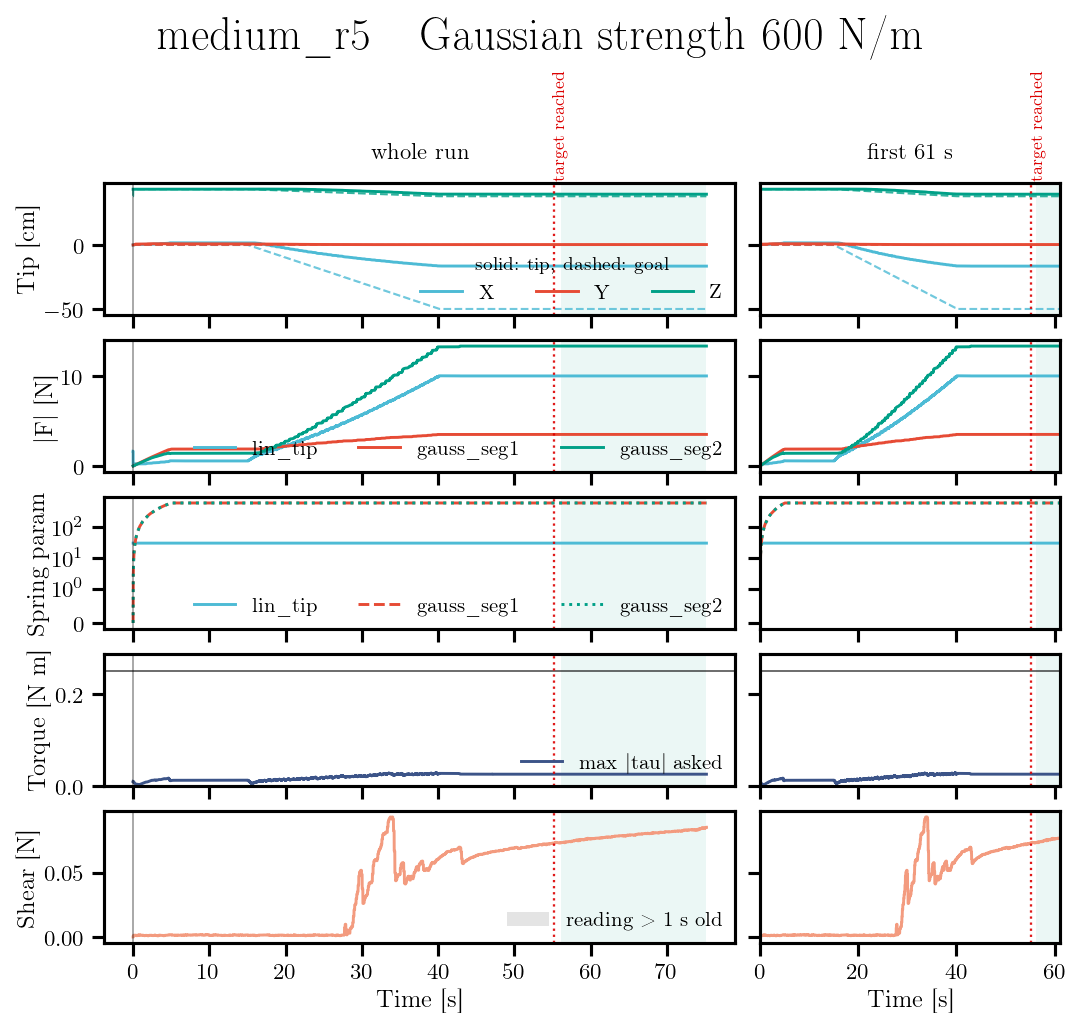

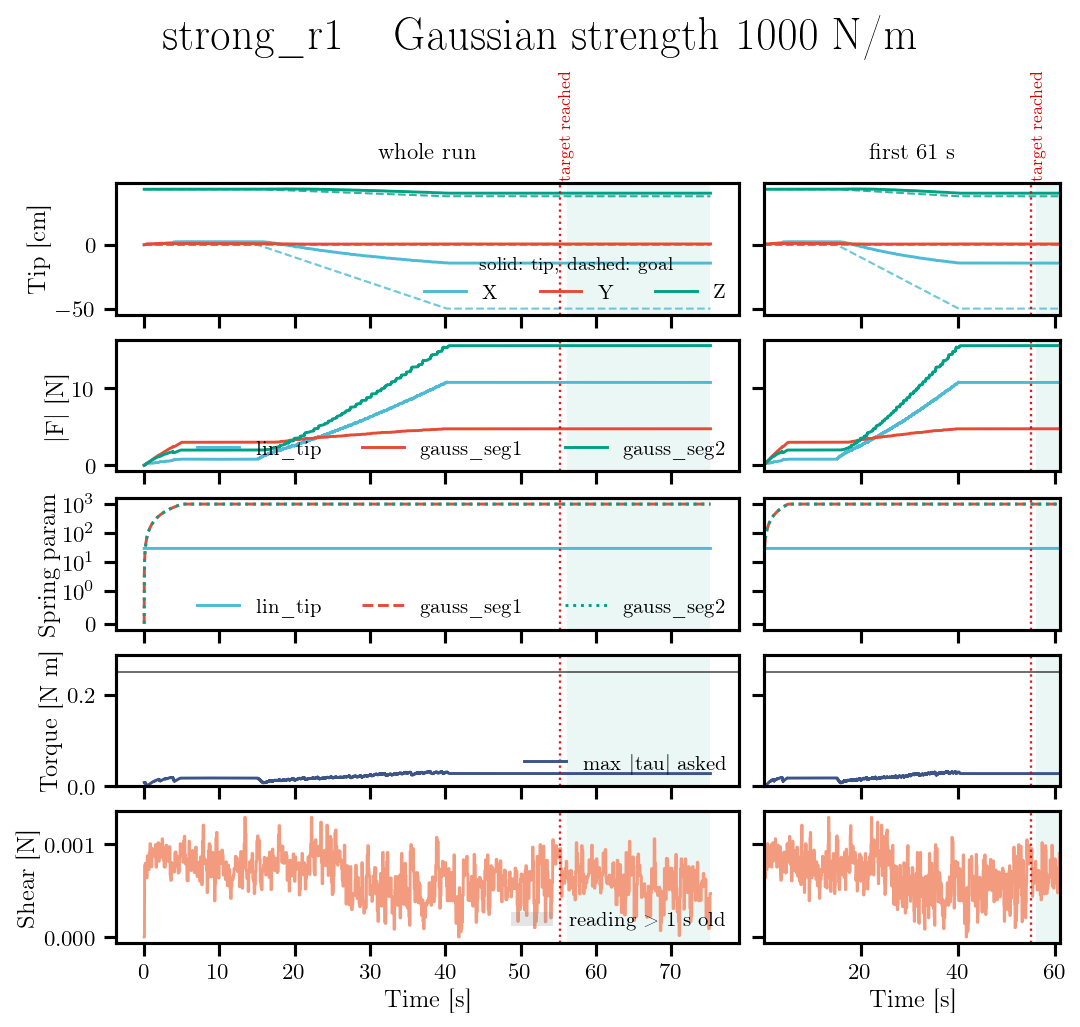

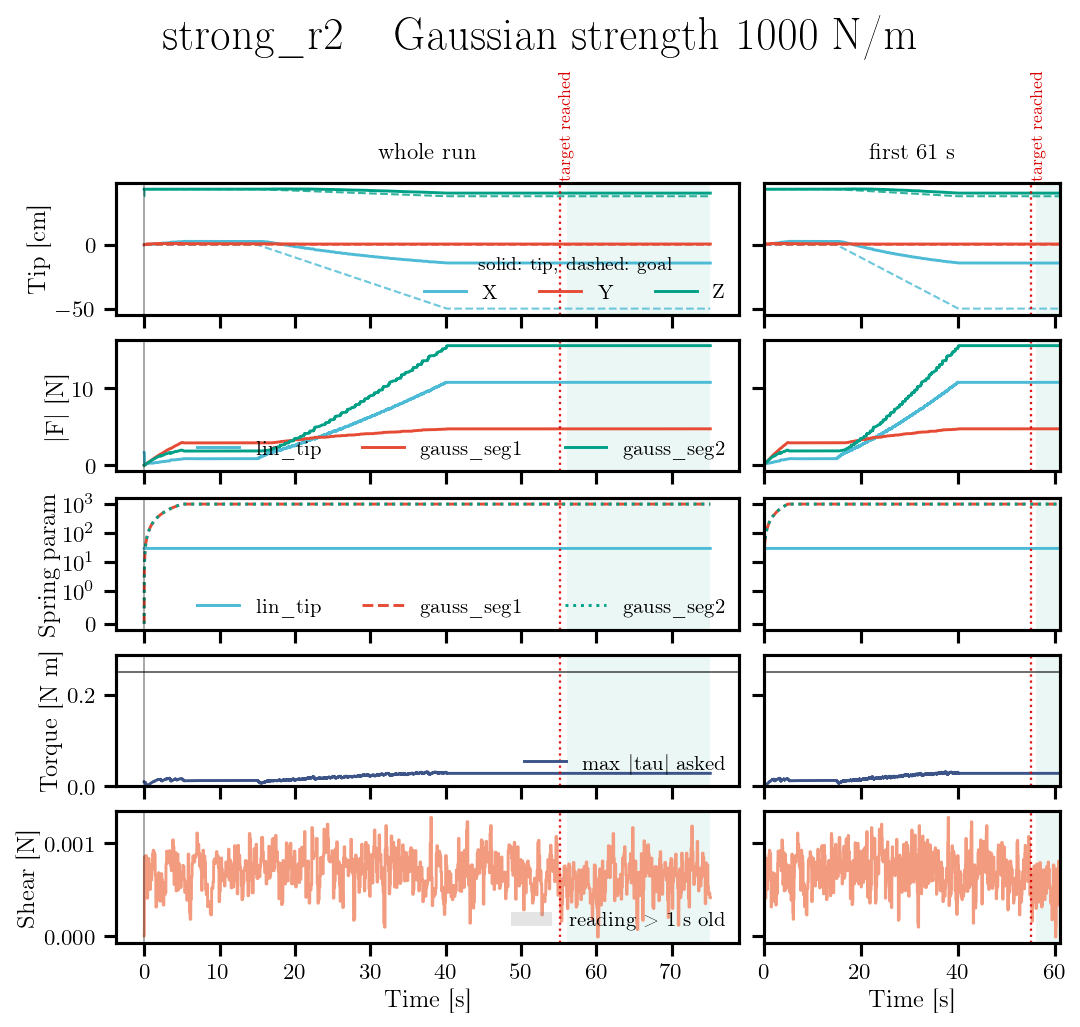

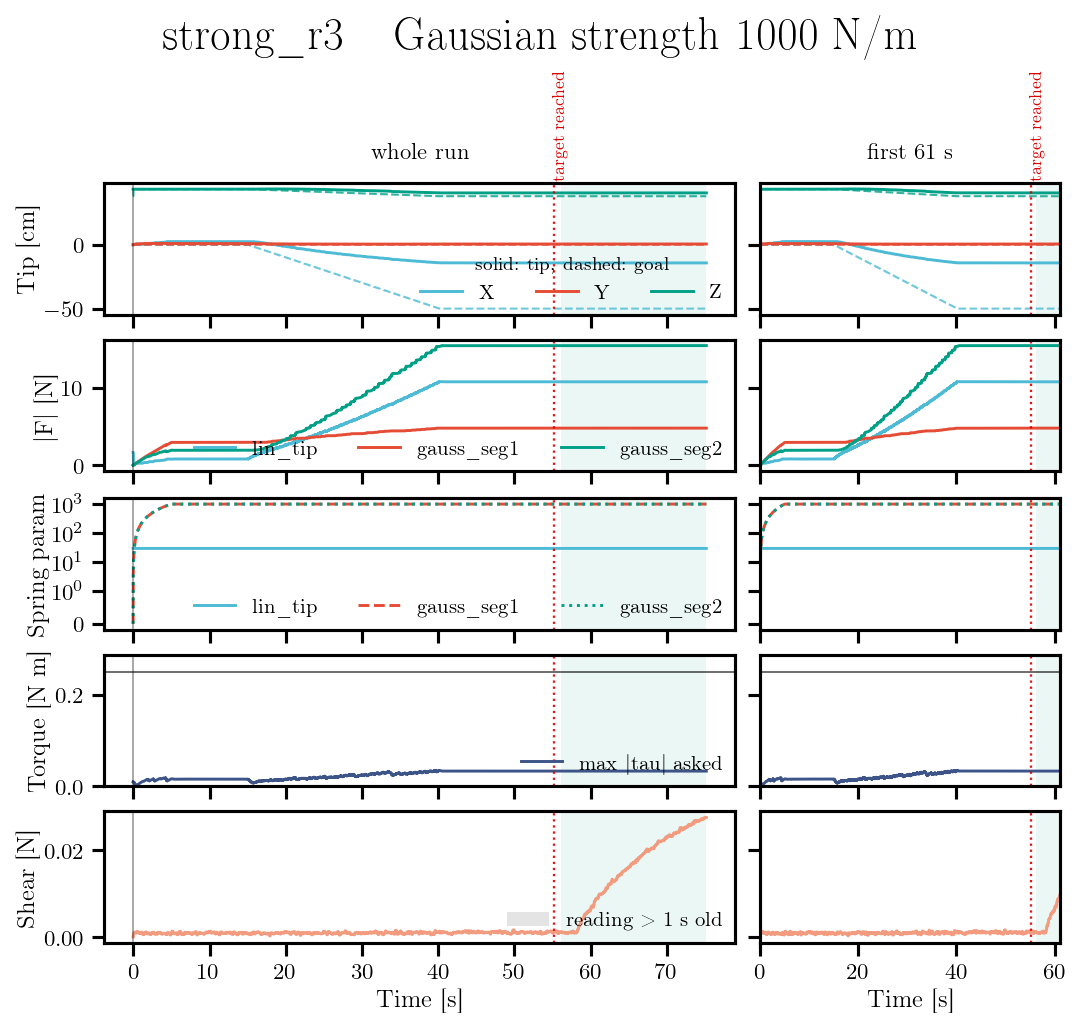

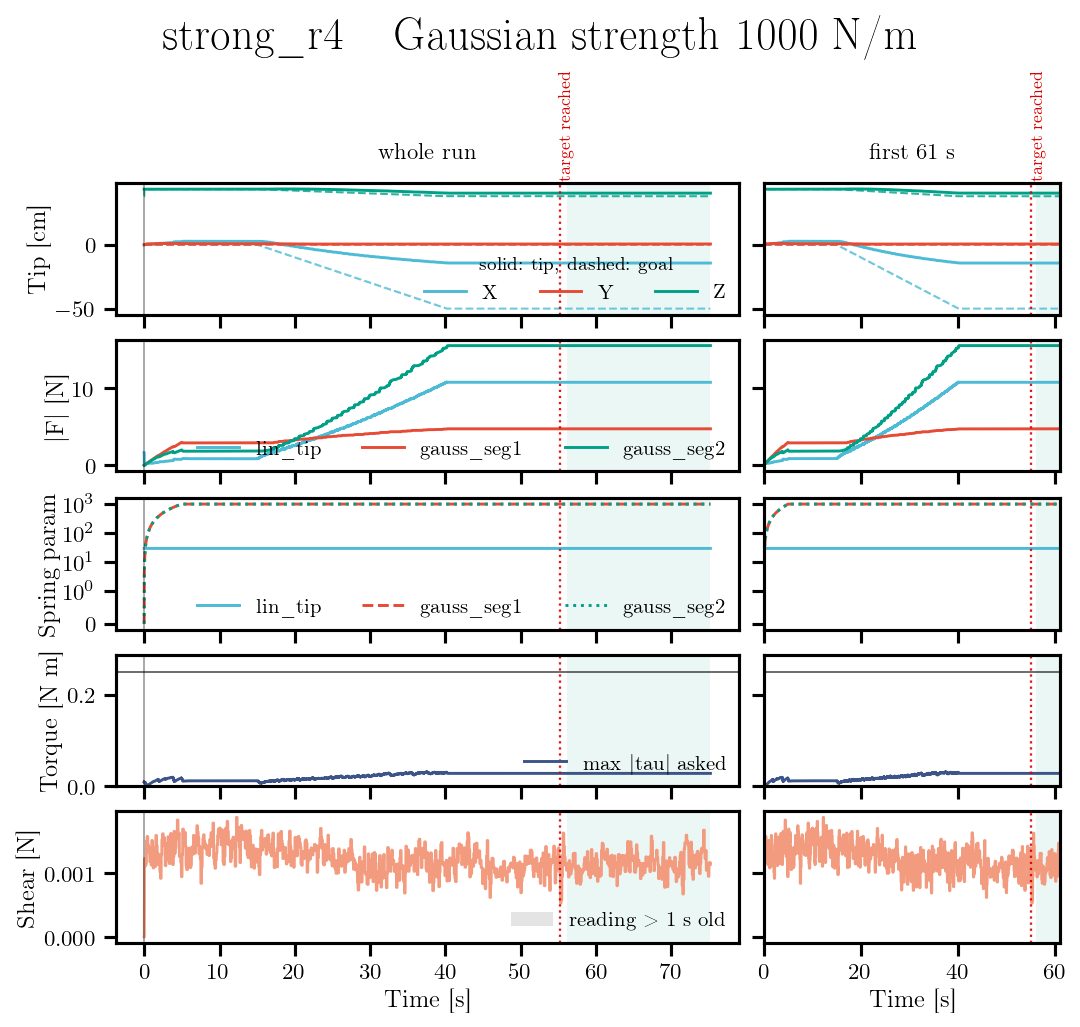

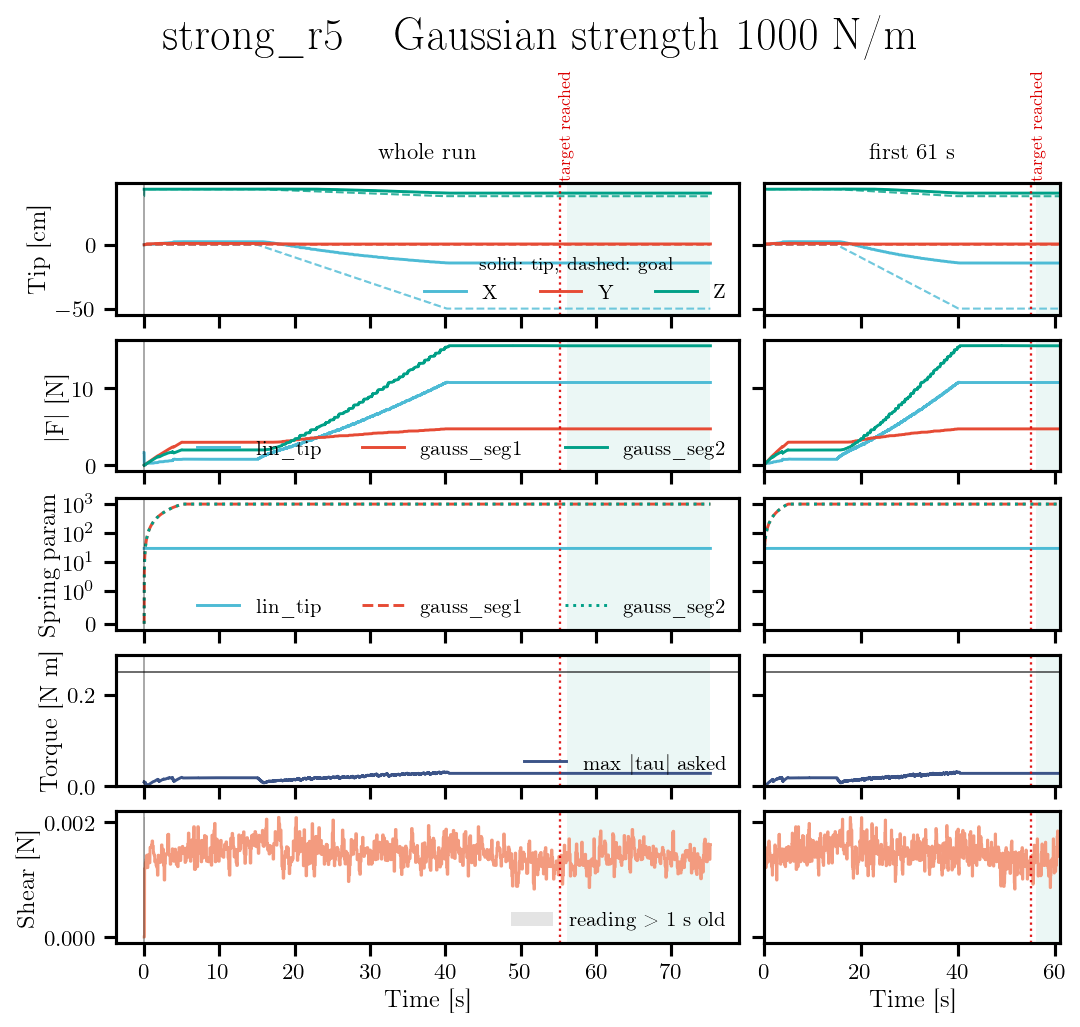

In [4]:
def plot_run(r, folder=None, zoom_pad=5.0):
    """One run, top to bottom, twice: the whole thing on the left and the
    opening transient on the right. Everything that matters -- the take-up, the
    ramp, the goal being dragged into place -- happens in the first seconds and
    is a single pixel wide on a 5-minute axis. Rows needing a channel the file
    does not have are left out rather than drawn empty."""
    t, hold = r['t'], r['hold']
    rows = ['pos', 'force_el', 'k', 'tau'] + (['load'] if r['force_live'] else [])
    # A diagnostic figure, not a paper one: five stacked rows do not fit the
    # paper font size, so it is shrunk here and nowhere else.
    with plt.rc_context({'axes.labelsize': 12, 'xtick.labelsize': 11,
                         'ytick.labelsize': 11, 'axes.titlesize': 12}):
        return _plot_run(r, rows, folder, zoom_pad)


def _plot_run(r, rows, folder, zoom_pad):
    t, hold = r['t'], r['hold']
    fig, axes = plt.subplots(len(rows), 2, sharex='col', sharey='row',
                             figsize=(FIG_W_DOUBLE, 0.95 * FIG_W_DOUBLE),
                             layout='constrained',
                             gridspec_kw=dict(width_ratios=[2.1, 1]))
    ax = {name: dict(full=axes[i, 0], zoom=axes[i, 1]) for i, name in enumerate(rows)}
    tau_max = np.abs(r['tau_raw']).max(axis=1)

    def draw(a, row, legend):
        if row == 'pos':
            # where the tip is, against where it was asked to be, per axis
            for j, lbl in enumerate('XYZ'):
                a.plot(t, r['comp_pos'][:, 0, j] * 100, color=COLORS[j], linewidth=1.4, label=lbl)
                a.plot(t, r['goal'][:, 0, j] * 100, '--', color=COLORS[j], linewidth=1.0, alpha=0.8)
            if legend:
                a.set_ylabel('Tip [cm]')
                a.legend(ncol=3, fontsize=10, loc='lower right',
                         title='solid: tip,  dashed: goal', title_fontsize=9)
        elif row == 'force_el':
            # what each element is actually pulling with
            if r['f_comp'] is not None:
                for i, nm in enumerate(r['comp_names']):
                    a.plot(t, np.linalg.norm(r['f_comp'][:, i], axis=1), color=COLORS[i],
                           linewidth=1.4, label=nm)
            else:
                a.plot(t, np.linalg.norm(r['raw']['f_virtual'], axis=1), color=COLORS[9],
                       linewidth=1.4, label='sum over elements')
            if legend:
                a.set_ylabel('|F| [N]' if r['f_comp'] is not None else '|sum F| [N]')
                a.legend(ncol=3, fontsize=10, loc='lower right')
                if r['f_comp'] is None:
                    a.text(0.01, 0.95, 'per-element forces not logged in this run',
                           transform=a.transAxes, fontsize=9, va='top', color=COLORS[1])
        elif row == 'k':
            # the parameters, which is where the ramp and any slider move show up
            for i, nm in enumerate(r['comp_names']):
                a.plot(t, r['k_params'][:, i], color=COLORS[i], linewidth=1.4,
                       linestyle=['-', '--', ':'][i % 3], label=nm)
            a.set_yscale('symlog', linthresh=1.0)
            if legend:
                a.set_ylabel('Spring param')
                a.legend(ncol=3, fontsize=10, loc='lower right')
        elif row == 'tau':
            # how close the limiter came, and where it bit
            a.plot(t, tau_max, color=COLORS[3], linewidth=1.4, label='max |tau| asked')
            a.axhline(r['tau_limit'], color='k', linewidth=0.9, alpha=0.6)
            if r['clipped'].any():
                a.fill_between(t, 0, tau_max, where=r['clipped'], color=COLORS[7], alpha=0.25,
                               linewidth=0, label=f"clipped ({100*r['clipped'].mean():.0f}% of run)")
            a.set_ylim(0, r['tau_limit'] * 1.15)
            if legend:
                a.set_ylabel('Torque [N m]')
                a.legend(fontsize=10, loc='lower right')
        elif row == 'load':
            a.plot(t, r['force_n'], color=COLORS[4], linewidth=1.4)
            if r['force_age'] is not None:
                stale = np.nan_to_num(r['force_age'], nan=1e3) > 1.0
                if stale.any():
                    a.fill_between(t, r['force_n'].min(), r['force_n'].max(), where=stale,
                                   color=COLORS[9], alpha=0.25, linewidth=0,
                                   label='reading > 1 s old')
                    if legend:
                        a.legend(fontsize=10, loc='lower right')
            if legend:
                a.set_ylabel('Shear [N]')

    for name in rows:
        for which, a in ax[name].items():
            draw(a, name, legend=(which == 'full'))
            a.axvspan(t[hold][0], t[hold][-1], color=COLORS[2], alpha=0.08, linewidth=0, zorder=0)
            if r['has_pre']:
                a.axvline(0.0, color='k', linewidth=0.8, alpha=0.4)   # GUI connected here
            for mt, lbl in zip(r['marks_t'], r['marks_label']):
                a.axvline(mt, color=COLORS[7], linewidth=1.1, alpha=0.9, linestyle=':')
                if name == rows[0]:
                    a.text(mt, 1.01, f' {lbl}', transform=a.get_xaxis_transform(),
                           rotation=90, va='bottom', ha='left', fontsize=8, color=COLORS[7])
            a.grid(GRID)

    ax[rows[0]]['zoom'].set_xlim(t[0], t[hold][0] + zoom_pad)
    ax[rows[0]]['zoom'].set_title(f'first {t[hold][0] + zoom_pad - t[0]:.0f} s', fontsize=11)
    ax[rows[0]]['full'].set_title('whole run', fontsize=11)
    for a in axes[-1]:
        a.set_xlabel('Time [s]')
    fig.suptitle(f"{r['name']}  --  Gaussian strength {r['strength']:.0f} N/m")
    if folder:
        save_fig(fig, folder, f"run_{r['name']}")
    plt.show()


for r in runs_b:
    plot_run(r, folder='button_pressing')

### Geometry

Three views of the same steady pose. The two projections carry the sigma silhouette, which is
where a flat reading goes wrong: a backbone that falls inside the circle in one projection can
still be a long way from the obstacle. The right-hand panel is the distance in 3-D from every
point of the backbone to the obstacle centre, and it is the one to read against sigma.

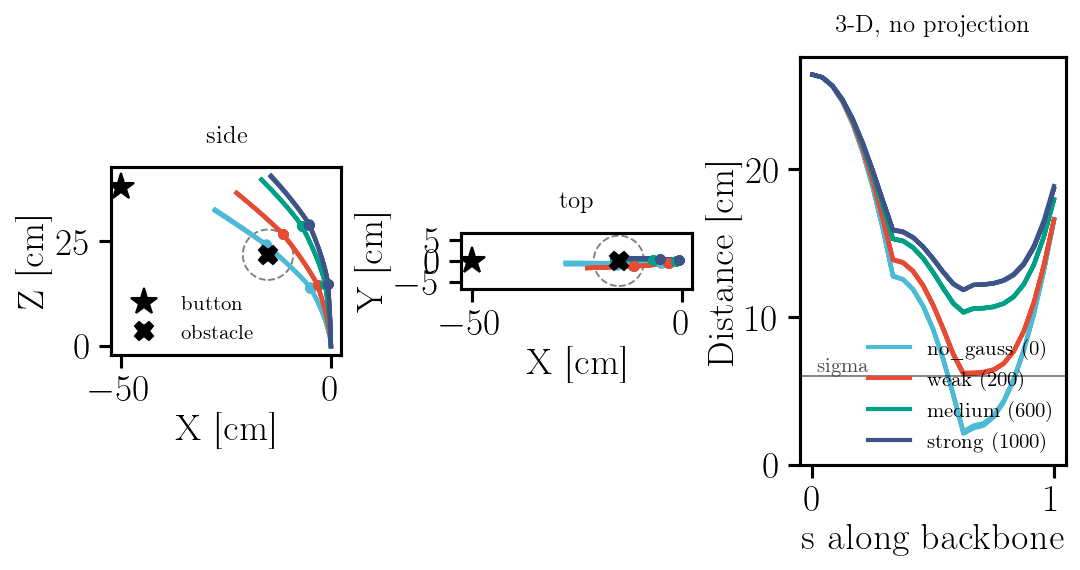

In [5]:
def plot_geometry(runs, cfg, folder, obstacle_label='obstacle', name='backbone'):
    fig, (ax_xz, ax_xy, ax_d) = plt.subplots(
        1, 3, figsize=(FIG_W_DOUBLE, 0.52 * FIG_W_DOUBLE), layout='constrained',
        gridspec_kw=dict(width_ratios=[1, 1, 1.15]))

    obs = runs[0]['obstacle']
    tgt = runs[0]['target']
    conds = sorted({r['condition'] for r in runs},
                   key=lambda c: next(x['strength'] for x in runs if x['condition'] == c))
    seen  = set()
    for r in runs:
        i   = conds.index(r['condition'])          # colour by condition, not by file
        b   = backbone(r)
        lbl = None if r['condition'] in seen else f"{r['condition']} ({r['strength']:.0f})"
        seen.add(r['condition'])
        ax_xz.plot(b[:, 0] * 100, b[:, 2] * 100, color=COLORS[i], linewidth=2.0,
                   alpha=0.85, zorder=3, label=lbl)
        ax_xy.plot(b[:, 0] * 100, b[:, 1] * 100, color=COLORS[i], linewidth=2.0, zorder=3)
        ax_d.plot(S_BACKBONE, np.linalg.norm(b - r['obstacle'], axis=1) * 100,
                  color=COLORS[i], linewidth=2.0, label=lbl)
        for s in r['s_params'][1:]:            # the Gaussian attachment points
            p = b[np.argmin(np.abs(S_BACKBONE - s))]
            ax_xz.plot(p[0] * 100, p[2] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)
            ax_xy.plot(p[0] * 100, p[1] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)

    for a, (u, v), (ul, vl) in ((ax_xz, (0, 2), ('X [cm]', 'Z [cm]')),
                                (ax_xy, (0, 1), ('X [cm]', 'Y [cm]'))):
        a.plot(tgt[u] * 100, tgt[v] * 100, '*', color='k', markersize=13, zorder=5, label='button')
        a.plot(obs[u] * 100, obs[v] * 100, 'X', color='k', markersize=9, zorder=5, label=obstacle_label)
        # The true silhouette of a sphere of radius sigma -- and the trap: a
        # backbone drawn inside it is not necessarily within sigma in 3-D.
        a.add_patch(plt.Circle((obs[u] * 100, obs[v] * 100), cfg.SIGMA * 100, fill=False,
                               linestyle='--', color='k', linewidth=0.9, alpha=0.5, zorder=2))
        a.set_xlabel(ul); a.set_ylabel(vl)
        a.set_aspect('equal'); a.grid(GRID)

    ax_xz.set_title('side', fontsize=12)
    ax_xy.set_title('top', fontsize=12)
    h, l = ax_xz.get_legend_handles_labels()
    ax_xz.legend(h[-2:], l[-2:], fontsize=10, loc='lower left', framealpha=0.9)

    # Same horizontal scale in both projections, so the two views can be read
    # against each other rather than as two unrelated pictures.
    xlim = (min(ax_xz.get_xlim()[0], ax_xy.get_xlim()[0]),
            max(ax_xz.get_xlim()[1], ax_xy.get_xlim()[1]))
    ax_xz.set_xlim(*xlim)
    ax_xy.set_xlim(*xlim)

    ax_d.axhline(cfg.SIGMA * 100, color='k', linewidth=0.9, alpha=0.5)
    ax_d.text(0.02, cfg.SIGMA * 100, ' sigma', va='bottom', fontsize=10, color='k', alpha=0.7)
    ax_d.set_title('3-D, no projection', fontsize=12)
    ax_d.set_xlabel('s along backbone')
    ax_d.set_ylabel('Distance [cm]')
    ax_d.set_ylim(0, None)
    ax_d.grid(GRID)
    ax_d.legend(fontsize=10, loc='lower right')

    save_fig(fig, folder, name)
    plt.show()


if runs_b:
    plot_geometry(runs_b, cfg_b, 'button_pressing', obstacle_label='obstacle')

### Contact force

Only worth reading where the load cell was actually publishing -- a run recorded without
`arduino_force.py` logs a channel of exact zeros, which plots as a perfectly flat line rather
than as nothing. `arduino_force.py` publishes `-force_shear`, so check the sign before
trusting the axis.

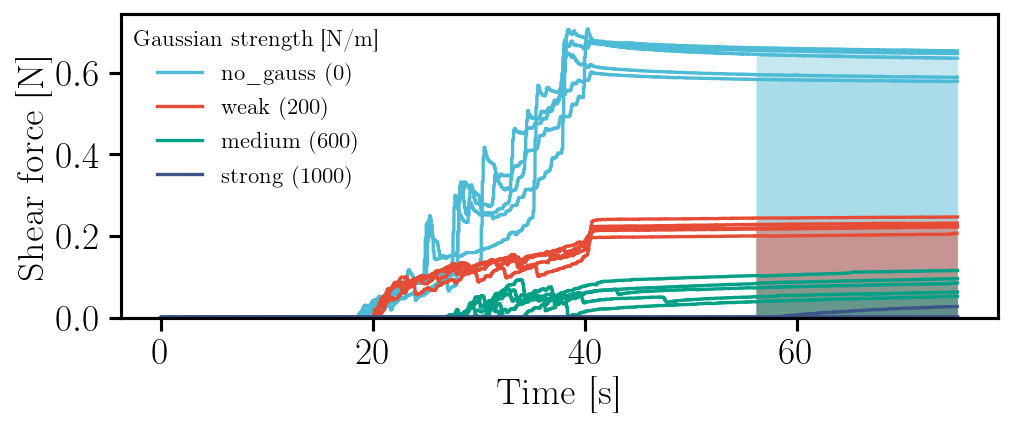

In [6]:
live_b = [r for r in runs_b if r['force_live']]
if not runs_b:
    print('outputs/button_pressing/ is empty -- nothing to plot.')
elif not live_b:
    print('No run in button_pressing has a live load-cell channel -- '
          'force is identically zero in: ' + ', '.join(r['name'] for r in runs_b))
else:
    # Colour by condition, not by file: with 5 repeats there are 20 runs and only
    # 10 colours, and the repeats of one condition belong together anyway.
    conds = sorted({r['condition'] for r in live_b},
                   key=lambda c: next(x['strength'] for x in live_b if x['condition'] == c))
    seen  = set()
    fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.45))
    for r in live_b:
        i   = conds.index(r['condition'])
        lbl = None if r['condition'] in seen else f"{r['condition']} ({r['strength']:.0f})"
        seen.add(r['condition'])
        ax.plot(r['t'], r['force_n'], color=COLORS[i], linewidth=1.6, label=lbl)
        ax.fill_between(r['t'], 0, r['force_n'], where=r['hold'], color=COLORS[i],
                        alpha=0.12, linewidth=0)
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Shear force [N]')
    ax.set_ylim(min(0.0, min(r['force_n'].min() for r in live_b)), None)
    ax.grid(GRID)
    ax.legend(title='Gaussian strength [N/m]', fontsize=11, title_fontsize=11)
    fig.tight_layout()
    save_fig(fig, 'button_pressing', 'force_vs_time')
    plt.show()


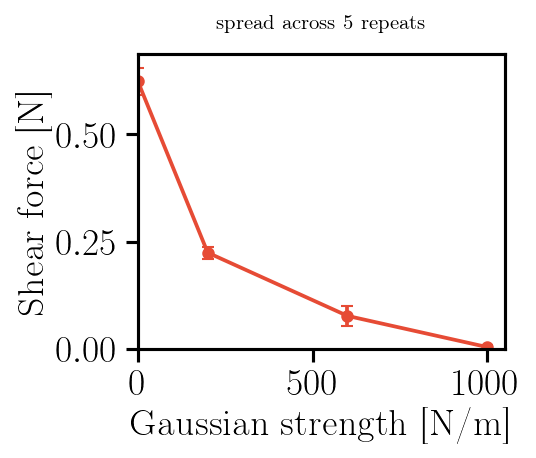

In [7]:
# Steady-state contact force against Gaussian strength.
# With repeats, each condition contributes several recordings: the point is the
# mean across them and the bar their spread, which is what a repeated sweep is
# for. Without repeats it falls back to the within-window spread of the one run.
if len(live_b) < 2:
    print(f'{len(live_b)} run(s) with a live load cell -- nothing to sweep yet.')
else:
    by_cond = {}
    for r in live_b:
        by_cond.setdefault(r['condition'], []).append(r['force_n'][r['hold']].mean())
    conds    = sorted(by_cond, key=lambda c: next(r['strength'] for r in live_b
                                                  if r['condition'] == c))
    strength = np.array([next(r['strength'] for r in live_b if r['condition'] == c)
                         for c in conds])
    f_mean   = np.array([np.mean(by_cond[c]) for c in conds])
    n_rep    = np.array([len(by_cond[c]) for c in conds])
    if (n_rep > 1).any():
        f_err = np.array([np.std(by_cond[c]) for c in conds])
        note  = ('spread across %d repeats' % n_rep.min() if n_rep.min() == n_rep.max()
                 else f'spread across {n_rep.min()}-{n_rep.max()} repeats')
    else:
        f_err = np.array([r['force_n'][r['hold']].std()
                          for c in conds for r in live_b if r['condition'] == c])
        note  = 'within-window spread (1 run per condition)'

    fig, ax = plt.subplots(figsize=(FIG_W_SINGLE, FIG_W_SINGLE * 0.85),
                           layout='constrained')
    ax.errorbar(strength, f_mean, yerr=f_err, marker='o', color=COLORS[1],
                linewidth=1.8, markersize=5, capsize=3)
    ax.set_xlabel(r'Gaussian strength [N/m]')
    ax.set_ylabel('Shear force [N]')
    ax.set_xlim(0, None)
    ax.set_ylim(min(0.0, f_mean.min()), None)
    ax.grid(GRID)
    ax.set_title(note, fontsize=10)
    save_fig(fig, 'button_pressing', 'force_vs_strength')
    plt.show()